In [1]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
!pip -q install kagglehub polars timm transformers

In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "theibrarbashir/military-vs-civilian-vehicle-image-classification"
)

print("Dataset:", dataset_path)

100%|██████████| 128M/128M [00:00<00:00, 247MB/s]

Extracting files...


Dataset: /root/.cache/kagglehub/datasets/theibrarbashir/military-vs-civilian-vehicle-image-classification/versions/1


In [4]:
import os

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

    if level >= 2:
        dirs[:] = []

1/
  Military vs Civilian Vehicle Image Classification/
    Training/
    Validation/
    Testing/


In [5]:
import os

base_path = os.path.join(
    dataset_path,
    "Military vs Civilian Vehicle Image Classification"
)

print("Base path:", base_path)
print()

for split in ["Training", "Validation", "Testing"]:
    split_path = os.path.join(base_path, split)

    print(f"===== {split} =====")

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            files = os.listdir(class_path)
            print(f"{class_name}: {len(files)} files")

    print()

Base path: /root/.cache/kagglehub/datasets/theibrarbashir/military-vs-civilian-vehicle-image-classification/versions/1/Military vs Civilian Vehicle Image Classification

===== Training =====
civilian aircraft: 812 files
civilian car: 871 files
military aircraft: 829 files
military helicopter: 993 files
military tank: 1373 files
military truck: 818 files

===== Validation =====
civilian aircraft: 143 files
civilian car: 153 files
military aircraft: 147 files
military helicopter: 175 files
military tank: 242 files
military truck: 145 files

===== Testing =====
civilian aircraft: 220 files
civilian car: 229 files
military aircraft: 228 files
military helicopter: 264 files
military tank: 358 files
military truck: 213 files



In [6]:
from PIL import Image
import os

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for split in ["Training", "Validation", "Testing"]:
    split_path = os.path.join(base_path, split)

    print(f"\n===== {split} =====")

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if not os.path.isdir(class_path):
            continue

        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(valid_extensions)
        ]

        if not images:
            continue

        sample = os.path.join(class_path, images[0])

        try:
            with Image.open(sample) as img:
                print(
                    f"{class_name}: "
                    f"{len(images)} images | "
                    f"sample: {img.size} | "
                    f"mode: {img.mode}"
                )
        except Exception as e:
            print(f"{class_name}: ERROR -> {e}")


===== Training =====
civilian aircraft: 812 images | sample: (408, 230) | mode: RGB
civilian car: 871 images | sample: (308, 164) | mode: RGB
military aircraft: 829 images | sample: (2000, 1334) | mode: RGB
military helicopter: 993 images | sample: (224, 224) | mode: RGB
military tank: 1373 images | sample: (960, 720) | mode: RGB
military truck: 818 images | sample: (224, 224) | mode: RGB

===== Validation =====
civilian aircraft: 143 images | sample: (224, 224) | mode: RGB
civilian car: 153 images | sample: (224, 224) | mode: RGB
military aircraft: 147 images | sample: (224, 224) | mode: RGB
military helicopter: 175 images | sample: (224, 224) | mode: RGB
military tank: 242 images | sample: (224, 224) | mode: RGB
military truck: 145 images | sample: (224, 224) | mode: RGB

===== Testing =====
civilian aircraft: 220 images | sample: (224, 224) | mode: RGB
civilian car: 229 images | sample: (275, 183) | mode: RGB
military aircraft: 228 images | sample: (224, 224) | mode: RGB
military h

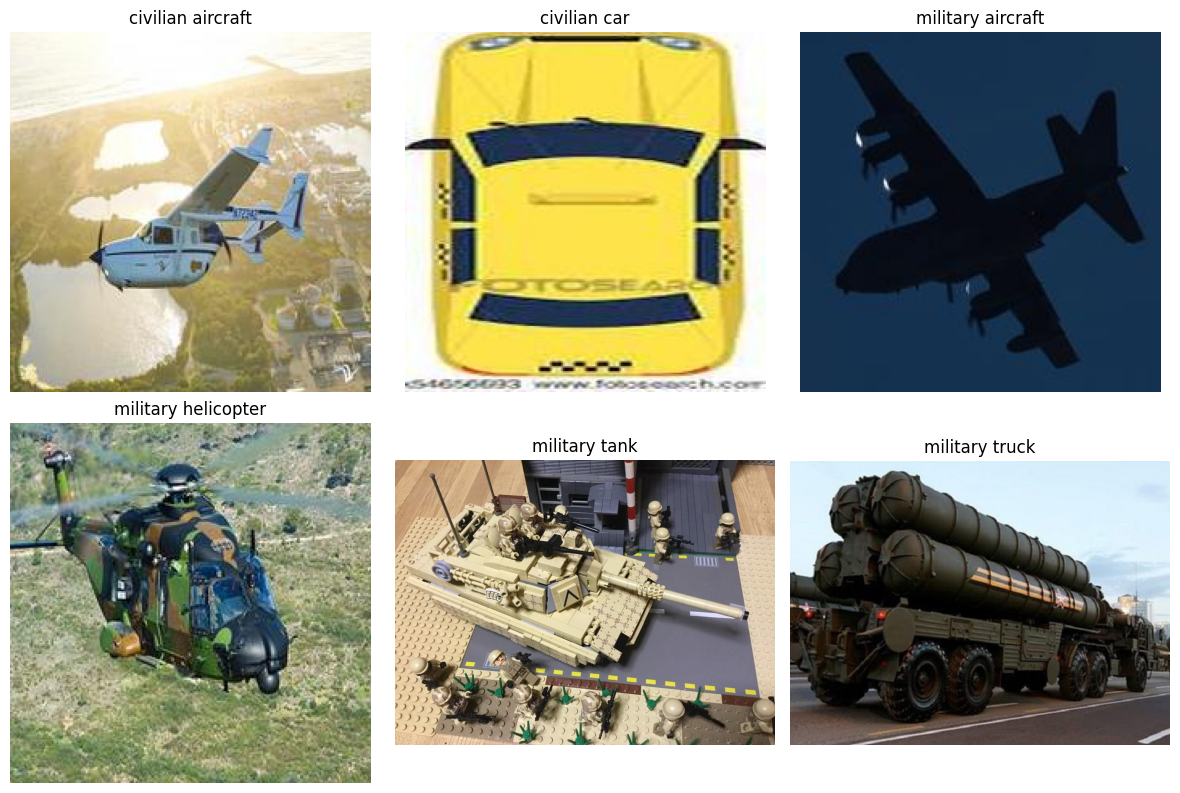

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

classes = sorted(os.listdir(os.path.join(base_path, "Training")))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, class_name in zip(axes.flat, classes):
    class_path = os.path.join(base_path, "Training", class_name)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    image_file = random.choice(images)

    image = Image.open(os.path.join(class_path, image_file))

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    os.path.join(base_path, "Training"),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    os.path.join(base_path, "Validation"),
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    os.path.join(base_path, "Testing"),
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Classes:", train_dataset.classes)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Classes: ['civilian aircraft', 'civilian car', 'military aircraft', 'military helicopter', 'military tank', 'military truck']
Training: 5696
Validation: 1005
Testing: 1512


In [9]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


class BaselineCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = BaselineCNN(num_classes=6).to(device)

print(model)

Device: cuda
GPU: Tesla T4
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=256, out_features=6, bias=True)
  )
)


In [10]:
import random
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score, classification_report
import copy
import time

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Training configuration
EPOCHS = 15
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

best_f1 = 0.0
best_state = None

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

print("Training configuration ready.")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

Training configuration ready.
Epochs: 15
Learning rate: 0.001
Weight decay: 0.0001


In [11]:
from tqdm.auto import tqdm
import time
import copy

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} [Train]"
    )

    for images, labels in train_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    val_loss /= val_total
    val_acc = val_correct / val_total

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    # Learning-rate scheduler
    scheduler.step(val_f1)

    current_lr = optimizer.param_groups[0]["lr"]

    # Save history
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    # Save best model
    if val_f1 > best_f1:

        best_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())

        print("  ✓ New best validation F1")

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"LR: {current_lr:.6f}"
    )

# Restore best model
model.load_state_dict(best_state)

print("\n===================================")
print("Baseline training complete")
print(f"Best validation Macro-F1: {best_f1:.4f}")
print("===================================")

Epoch 1/15 [Train]:   0%|          | 0/178 [00:00<?, ?it/s]

  ✓ New best validation F1

Epoch 1/15 | Train Loss: 1.6412 | Train Acc: 0.3064 | Val Loss: 1.5361 | Val Acc: 0.3512 | Val Macro-F1: 0.2591 | LR: 0.001000


Epoch 2/15 [Train]:   0%|          | 0/178 [00:00<?, ?it/s]

  ✓ New best validation F1

Epoch 2/15 | Train Loss: 1.5131 | Train Acc: 0.3722 | Val Loss: 1.4464 | Val Acc: 0.4030 | Val Macro-F1: 0.3708 | LR: 0.001000


Epoch 3/15 [Train]:   0%|          | 0/178 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7acb4d029f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7acb4d029f80><function _MultiProcessingDataLoaderIter.__del__ at 0x7acb4d029f80>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/u

  ✓ New best validation F1

Epoch 14/15 | Train Loss: 0.9876 | Train Acc: 0.6401 | Val Loss: 0.8905 | Val Acc: 0.6527 | Val Macro-F1: 0.6340 | LR: 0.001000


Epoch 15/15 [Train]:   0%|          | 0/178 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7acb4d029f80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7acb4d029f80>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7acb4d029f80>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/tor

  ✓ New best validation F1

Epoch 15/15 | Train Loss: 0.9399 | Train Acc: 0.6554 | Val Loss: 0.9322 | Val Acc: 0.6587 | Val Macro-F1: 0.6497 | LR: 0.001000

Baseline training complete
Best validation Macro-F1: 0.6497


In [12]:
# Recreate DataLoaders without multiprocessing
# This avoids the worker-cleanup warnings seen in Colab.

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders recreated successfully.")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders recreated successfully.
Training batches: 178
Validation batches: 32
Test batches: 48


In [13]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_test_labels = []
all_test_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_test_labels.extend(labels.cpu().numpy())
        all_test_predictions.extend(predictions.cpu().numpy())

# Overall metrics
test_accuracy = accuracy_score(
    all_test_labels,
    all_test_predictions
)

test_macro_f1 = f1_score(
    all_test_labels,
    all_test_predictions,
    average="macro"
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")

# Per-class metrics
print("\nClassification Report:\n")

print(
    classification_report(
        all_test_labels,
        all_test_predictions,
        target_names=train_dataset.classes,
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(
    all_test_labels,
    all_test_predictions
)

print("\nConfusion Matrix:")
print(cm)

Test Accuracy: 0.6442
Test Macro-F1: 0.6381

Classification Report:

                     precision    recall  f1-score   support

  civilian aircraft     0.5157    0.8227    0.6340       220
       civilian car     0.6856    0.7904    0.7343       229
  military aircraft     0.6138    0.3904    0.4772       228
military helicopter     0.7952    0.6326    0.7046       264
      military tank     0.8170    0.5363    0.6476       358
     military truck     0.5342    0.7700    0.6308       213

           accuracy                         0.6442      1512
          macro avg     0.6603    0.6571    0.6381      1512
       weighted avg     0.6790    0.6442    0.6406      1512


Confusion Matrix:
[[181   9  18   8   2   2]
 [ 21 181   3   1   5  18]
 [ 91  15  89  23   1   9]
 [ 38  16  22 167  17   4]
 [ 17  20   9  10 192 110]
 [  3  23   4   1  18 164]]


In [14]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load ImageNet-pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT

model_tl = efficientnet_b0(weights=weights)

# Replace the final classifier for our 6 classes
num_features = model_tl.classifier[1].in_features

model_tl.classifier[1] = nn.Linear(
    num_features,
    6
)

model_tl = model_tl.to(device)

print(model_tl)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 145MB/s]


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [15]:
EPOCHS_TL = 10
LEARNING_RATE_TL = 3e-4
WEIGHT_DECAY_TL = 1e-4

criterion_tl = nn.CrossEntropyLoss()

optimizer_tl = torch.optim.AdamW(
    model_tl.parameters(),
    lr=LEARNING_RATE_TL,
    weight_decay=WEIGHT_DECAY_TL
)

scheduler_tl = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_tl,
    mode="max",
    factor=0.5,
    patience=2
)

best_f1_tl = 0.0
best_state_tl = None

history_tl = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

print("Transfer-learning training setup complete.")

Transfer-learning training setup complete.


In [16]:
import time
from sklearn.metrics import f1_score, accuracy_score

start_time = time.time()

for epoch in range(EPOCHS_TL):

    # -------------------------
    # Training
    # -------------------------
    model_tl.train()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_tl.zero_grad()

        outputs = model_tl(images)
        loss = criterion_tl(outputs, labels)

        loss.backward()
        optimizer_tl.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = train_correct / train_total

    # -------------------------
    # Validation
    # -------------------------
    model_tl.eval()

    val_running_loss = 0.0
    val_labels = []
    val_predictions = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_tl(images)
            loss = criterion_tl(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_labels.extend(labels.cpu().numpy())
            val_predictions.extend(predictions.cpu().numpy())

    val_loss = val_running_loss / len(val_dataset)

    val_acc = accuracy_score(
        val_labels,
        val_predictions
    )

    val_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    # Store history
    history_tl["train_loss"].append(train_loss)
    history_tl["train_acc"].append(train_acc)
    history_tl["val_loss"].append(val_loss)
    history_tl["val_acc"].append(val_acc)
    history_tl["val_f1"].append(val_f1)

    # Learning-rate scheduler
    scheduler_tl.step(val_f1)

    # Save best model state
    if val_f1 > best_f1_tl:
        best_f1_tl = val_f1
        best_state_tl = {
            key: value.detach().cpu().clone()
            for key, value in model_tl.state_dict().items()
        }

    current_lr = optimizer_tl.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS_TL} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"LR: {current_lr:.6f}"
    )

training_time_tl = time.time() - start_time

# Restore best validation model
model_tl.load_state_dict(best_state_tl)

print("\nTraining complete.")
print(f"Best Validation Macro-F1: {best_f1_tl:.4f}")
print(f"Training Time: {training_time_tl / 60:.2f} minutes")

Epoch 01/10 | Train Loss: 0.5922 | Train Acc: 0.8067 | Val Loss: 0.2633 | Val Acc: 0.9224 | Val Macro-F1: 0.9178 | LR: 0.000300
Epoch 02/10 | Train Loss: 0.2876 | Train Acc: 0.9048 | Val Loss: 0.2279 | Val Acc: 0.9323 | Val Macro-F1: 0.9282 | LR: 0.000300
Epoch 03/10 | Train Loss: 0.2244 | Train Acc: 0.9263 | Val Loss: 0.2400 | Val Acc: 0.9363 | Val Macro-F1: 0.9317 | LR: 0.000300
Epoch 04/10 | Train Loss: 0.1804 | Train Acc: 0.9377 | Val Loss: 0.2135 | Val Acc: 0.9433 | Val Macro-F1: 0.9390 | LR: 0.000300
Epoch 05/10 | Train Loss: 0.1560 | Train Acc: 0.9489 | Val Loss: 0.2284 | Val Acc: 0.9443 | Val Macro-F1: 0.9400 | LR: 0.000300
Epoch 06/10 | Train Loss: 0.1239 | Train Acc: 0.9575 | Val Loss: 0.2311 | Val Acc: 0.9473 | Val Macro-F1: 0.9442 | LR: 0.000300
Epoch 07/10 | Train Loss: 0.1183 | Train Acc: 0.9582 | Val Loss: 0.2312 | Val Acc: 0.9413 | Val Macro-F1: 0.9368 | LR: 0.000300
Epoch 08/10 | Train Loss: 0.1019 | Train Acc: 0.9647 | Val Loss: 0.2052 | Val Acc: 0.9542 | Val Macro-F1

In [17]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model_tl.eval()

test_labels = []
test_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model_tl(images)

        predictions = outputs.argmax(dim=1)

        test_labels.extend(labels.numpy())
        test_predictions.extend(predictions.cpu().numpy())


test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro"
)

print(f"EfficientNet-B0 Test Accuracy: {test_accuracy:.4f}")
print(f"EfficientNet-B0 Test Macro-F1: {test_macro_f1:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=test_dataset.classes,
        digits=4
    )
)

print("\nConfusion Matrix:\n")

print(
    confusion_matrix(
        test_labels,
        test_predictions
    )
)

EfficientNet-B0 Test Accuracy: 0.9411
EfficientNet-B0 Test Macro-F1: 0.9376

Classification Report:

                     precision    recall  f1-score   support

  civilian aircraft     0.9078    0.8955    0.9016       220
       civilian car     0.9567    0.9651    0.9609       229
  military aircraft     0.8933    0.8816    0.8874       228
military helicopter     0.9627    0.9773    0.9699       264
      military tank     0.9691    0.9637    0.9664       358
     military truck     0.9349    0.9437    0.9393       213

           accuracy                         0.9411      1512
          macro avg     0.9374    0.9378    0.9376      1512
       weighted avg     0.9409    0.9411    0.9410      1512


Confusion Matrix:

[[197   0  20   1   2   0]
 [  1 221   0   1   0   6]
 [ 16   2 201   6   3   0]
 [  1   1   3 258   1   0]
 [  1   2   1   1 345   8]
 [  1   5   0   1   5 201]]


In [18]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Fresh pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT

model_ft = efficientnet_b0(weights=weights)

# Replace classifier for our 6 classes
num_features = model_ft.classifier[1].in_features

model_ft.classifier[1] = nn.Linear(
    num_features,
    6
)

model_ft = model_ft.to(device)

print("Fresh EfficientNet-B0 created.")
print("Classes:", 6)
print("Classifier:", model_ft.classifier)

Fresh EfficientNet-B0 created.
Classes: 6
Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=6, bias=True)
)


In [19]:
# Freeze the pretrained EfficientNet backbone
for param in model_ft.features.parameters():
    param.requires_grad = False

# Keep only the classifier trainable
for param in model_ft.classifier.parameters():
    param.requires_grad = True

# Stage 1 configuration
EPOCHS_STAGE1 = 3
LR_STAGE1 = 1e-3
WEIGHT_DECAY_STAGE1 = 1e-4

criterion_ft = nn.CrossEntropyLoss()

optimizer_stage1 = torch.optim.AdamW(
    model_ft.classifier.parameters(),
    lr=LR_STAGE1,
    weight_decay=WEIGHT_DECAY_STAGE1
)

print("Stage 1 setup complete.")
print("Frozen backbone: YES")
print("Trainable classifier: YES")
print(f"Epochs: {EPOCHS_STAGE1}")
print(f"Learning rate: {LR_STAGE1}")

Stage 1 setup complete.
Frozen backbone: YES
Trainable classifier: YES
Epochs: 3
Learning rate: 0.001


In [20]:
import time
from sklearn.metrics import accuracy_score, f1_score

history_stage1 = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

best_f1_stage1 = 0.0
best_state_stage1 = None

start_time = time.time()

for epoch in range(EPOCHS_STAGE1):

    # -------------------------
    # Training
    # -------------------------
    model_ft.train()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_stage1.zero_grad()

        outputs = model_ft(images)
        loss = criterion_ft(outputs, labels)

        loss.backward()
        optimizer_stage1.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = train_correct / train_total

    # -------------------------
    # Validation
    # -------------------------
    model_ft.eval()

    val_running_loss = 0.0
    val_labels = []
    val_predictions = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_ft(images)
            loss = criterion_ft(outputs, labels)

            val_running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            val_labels.extend(labels.cpu().numpy())
            val_predictions.extend(
                predictions.cpu().numpy()
            )

    val_loss = val_running_loss / len(val_dataset)

    val_acc = accuracy_score(
        val_labels,
        val_predictions
    )

    val_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    history_stage1["train_loss"].append(train_loss)
    history_stage1["train_acc"].append(train_acc)
    history_stage1["val_loss"].append(val_loss)
    history_stage1["val_acc"].append(val_acc)
    history_stage1["val_f1"].append(val_f1)

    if val_f1 > best_f1_stage1:
        best_f1_stage1 = val_f1

        best_state_stage1 = {
            key: value.detach().cpu().clone()
            for key, value in model_ft.state_dict().items()
        }

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS_STAGE1} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

training_time_stage1 = time.time() - start_time

# Restore best Stage-1 checkpoint
model_ft.load_state_dict(best_state_stage1)

print("\nStage 1 complete.")
print(f"Best Stage-1 Validation Macro-F1: {best_f1_stage1:.4f}")
print(f"Training Time: {training_time_stage1 / 60:.2f} minutes")

Epoch 01/3 | Train Loss: 0.9593 | Train Acc: 0.6903 | Val Loss: 0.6094 | Val Acc: 0.8229 | Val Macro-F1: 0.8158
Epoch 02/3 | Train Loss: 0.6603 | Train Acc: 0.7783 | Val Loss: 0.5256 | Val Acc: 0.8308 | Val Macro-F1: 0.8253
Epoch 03/3 | Train Loss: 0.5915 | Train Acc: 0.8065 | Val Loss: 0.4777 | Val Acc: 0.8488 | Val Macro-F1: 0.8441

Stage 1 complete.
Best Stage-1 Validation Macro-F1: 0.8441
Training Time: 2.04 minutes


In [21]:
# Unfreeze the EfficientNet backbone
for param in model_ft.features.parameters():
    param.requires_grad = True

# Stage 2 configuration
EPOCHS_STAGE2 = 7
LR_STAGE2 = 1e-5
WEIGHT_DECAY_STAGE2 = 1e-4

optimizer_stage2 = torch.optim.AdamW(
    model_ft.parameters(),
    lr=LR_STAGE2,
    weight_decay=WEIGHT_DECAY_STAGE2
)

scheduler_stage2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage2,
    mode="max",
    factor=0.5,
    patience=2
)

print("Stage 2 setup complete.")
print("Frozen backbone: NO")
print("Full EfficientNet trainable: YES")
print(f"Epochs: {EPOCHS_STAGE2}")
print(f"Learning rate: {LR_STAGE2}")

Stage 2 setup complete.
Frozen backbone: NO
Full EfficientNet trainable: YES
Epochs: 7
Learning rate: 1e-05


In [22]:
import time
from sklearn.metrics import accuracy_score, f1_score

history_stage2 = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

best_f1_stage2 = 0.0
best_state_stage2 = None

start_time = time.time()

for epoch in range(EPOCHS_STAGE2):

    # -------------------------
    # Training
    # -------------------------
    model_ft.train()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_stage2.zero_grad()

        outputs = model_ft(images)
        loss = criterion_ft(outputs, labels)

        loss.backward()
        optimizer_stage2.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = train_correct / train_total

    # -------------------------
    # Validation
    # -------------------------
    model_ft.eval()

    val_running_loss = 0.0
    val_labels = []
    val_predictions = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_ft(images)
            loss = criterion_ft(outputs, labels)

            val_running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            val_labels.extend(labels.cpu().numpy())
            val_predictions.extend(
                predictions.cpu().numpy()
            )

    val_loss = val_running_loss / len(val_dataset)

    val_acc = accuracy_score(
        val_labels,
        val_predictions
    )

    val_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    history_stage2["train_loss"].append(train_loss)
    history_stage2["train_acc"].append(train_acc)
    history_stage2["val_loss"].append(val_loss)
    history_stage2["val_acc"].append(val_acc)
    history_stage2["val_f1"].append(val_f1)

    scheduler_stage2.step(val_f1)

    if val_f1 > best_f1_stage2:
        best_f1_stage2 = val_f1

        best_state_stage2 = {
            key: value.detach().cpu().clone()
            for key, value in model_ft.state_dict().items()
        }

    current_lr = optimizer_stage2.param_groups[0]["lr"]

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS_STAGE2} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"LR: {current_lr:.7f}"
    )

training_time_stage2 = time.time() - start_time

# Restore best Stage-2 checkpoint
model_ft.load_state_dict(best_state_stage2)

print("\nStage 2 complete.")
print(f"Best Stage-2 Validation Macro-F1: {best_f1_stage2:.4f}")
print(f"Training Time: {training_time_stage2 / 60:.2f} minutes")

Epoch 01/7 | Train Loss: 0.5265 | Train Acc: 0.8237 | Val Loss: 0.4201 | Val Acc: 0.8627 | Val Macro-F1: 0.8572 | LR: 0.0000100
Epoch 02/7 | Train Loss: 0.4669 | Train Acc: 0.8464 | Val Loss: 0.3706 | Val Acc: 0.8796 | Val Macro-F1: 0.8735 | LR: 0.0000100
Epoch 03/7 | Train Loss: 0.4332 | Train Acc: 0.8539 | Val Loss: 0.3402 | Val Acc: 0.8905 | Val Macro-F1: 0.8842 | LR: 0.0000100
Epoch 04/7 | Train Loss: 0.3944 | Train Acc: 0.8669 | Val Loss: 0.3113 | Val Acc: 0.8995 | Val Macro-F1: 0.8941 | LR: 0.0000100
Epoch 05/7 | Train Loss: 0.3757 | Train Acc: 0.8764 | Val Loss: 0.2943 | Val Acc: 0.9015 | Val Macro-F1: 0.8960 | LR: 0.0000100
Epoch 06/7 | Train Loss: 0.3433 | Train Acc: 0.8896 | Val Loss: 0.2804 | Val Acc: 0.9085 | Val Macro-F1: 0.9035 | LR: 0.0000100
Epoch 07/7 | Train Loss: 0.3319 | Train Acc: 0.8929 | Val Loss: 0.2696 | Val Acc: 0.9085 | Val Macro-F1: 0.9037 | LR: 0.0000100

Stage 2 complete.
Best Stage-2 Validation Macro-F1: 0.9037
Training Time: 6.77 minutes


In [23]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Make sure our champion model is being used
model_robust = model_tl
model_robust.eval()

print("Robustness Lab initialized.")
print("Champion model: EfficientNet-B0")
print("Baseline Test Accuracy: 94.11%")
print("Baseline Test Macro-F1: 93.76%")

Robustness Lab initialized.
Champion model: EfficientNet-B0
Baseline Test Accuracy: 94.11%
Baseline Test Macro-F1: 93.76%


In [24]:
from PIL import Image, ImageFilter, ImageEnhance
import random

def apply_corruption(image, corruption):
    """
    Apply a controlled corruption to a PIL image.
    Returns a PIL image.
    """

    if corruption == "gaussian_noise":
        img = np.array(image).astype(np.float32)

        noise = np.random.normal(
            loc=0.0,
            scale=25.0,
            size=img.shape
        )

        img = np.clip(
            img + noise,
            0,
            255
        ).astype(np.uint8)

        return Image.fromarray(img)

    elif corruption == "blur":
        return image.filter(
            ImageFilter.GaussianBlur(radius=2.0)
        )

    elif corruption == "brightness":
        return ImageEnhance.Brightness(
            image
        ).enhance(0.55)

    elif corruption == "contrast":
        return ImageEnhance.Contrast(
            image
        ).enhance(0.50)

    elif corruption == "low_resolution":
        width, height = image.size

        small = image.resize(
            (
                max(32, width // 8),
                max(32, height // 8)
            ),
            Image.Resampling.BILINEAR
        )

        return small.resize(
            (width, height),
            Image.Resampling.BILINEAR
        )

    else:
        return image


corruptions = [
    "clean",
    "gaussian_noise",
    "blur",
    "brightness",
    "contrast",
    "low_resolution"
]

print("Corruption pipeline ready.")
print("Conditions:", corruptions)

Corruption pipeline ready.
Conditions: ['clean', 'gaussian_noise', 'blur', 'brightness', 'contrast', 'low_resolution']


In [25]:
from sklearn.metrics import accuracy_score, f1_score

def evaluate_robustness(dataset, corruption):
    """
    Evaluate the champion EfficientNet under one corruption condition.
    """

    all_labels = []
    all_predictions = []

    for idx in range(len(dataset)):

        # Load original image directly from the ImageFolder
        image_path, label = dataset.samples[idx]

        image = Image.open(image_path).convert("RGB")

        # Apply corruption
        if corruption != "clean":
            image = apply_corruption(image, corruption)

        # Apply the same evaluation preprocessing
        image_tensor = eval_transform(image)

        # Add batch dimension
        image_tensor = image_tensor.unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model_robust(image_tensor)

        prediction = outputs.argmax(dim=1).item()

        all_labels.append(label)
        all_predictions.append(prediction)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return accuracy, macro_f1


robustness_results = {}

for corruption in corruptions:

    print(f"Evaluating: {corruption} ...")

    accuracy, macro_f1 = evaluate_robustness(
        test_dataset,
        corruption
    )

    robustness_results[corruption] = {
        "accuracy": accuracy,
        "macro_f1": macro_f1
    }

    print(
        f"  Accuracy: {accuracy:.4f} | "
        f"Macro-F1: {macro_f1:.4f}"
    )

print("\nRobustness evaluation complete.")

Evaluating: clean ...
  Accuracy: 0.9411 | Macro-F1: 0.9376
Evaluating: gaussian_noise ...
  Accuracy: 0.5556 | Macro-F1: 0.5401
Evaluating: blur ...
  Accuracy: 0.8724 | Macro-F1: 0.8627
Evaluating: brightness ...
  Accuracy: 0.9418 | Macro-F1: 0.9383
Evaluating: contrast ...
  Accuracy: 0.9392 | Macro-F1: 0.9355
Evaluating: low_resolution ...
  Accuracy: 0.7130 | Macro-F1: 0.6818

Robustness evaluation complete.


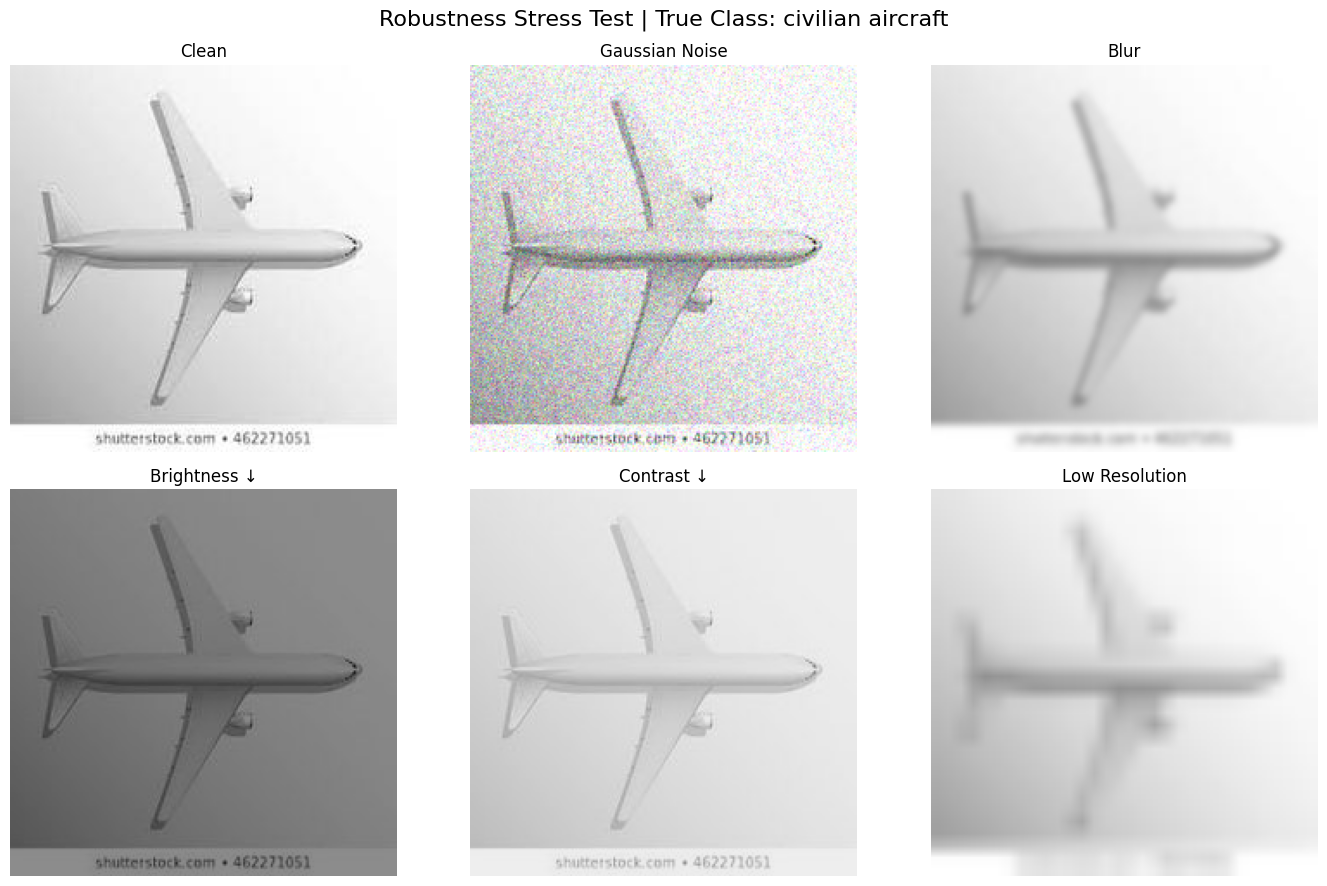

In [26]:
import matplotlib.pyplot as plt

# Pick a representative test image
sample_idx = 100

image_path, true_label = test_dataset.samples[sample_idx]

original_image = Image.open(image_path).convert("RGB")

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 9)
)

axes = axes.flatten()

titles = [
    "Clean",
    "Gaussian Noise",
    "Blur",
    "Brightness ↓",
    "Contrast ↓",
    "Low Resolution"
]

conditions_to_show = [
    "clean",
    "gaussian_noise",
    "blur",
    "brightness",
    "contrast",
    "low_resolution"
]

for ax, title, corruption in zip(
    axes,
    titles,
    conditions_to_show
):

    if corruption == "clean":
        display_image = original_image
    else:
        display_image = apply_corruption(
            original_image,
            corruption
        )

    ax.imshow(display_image)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

fig.suptitle(
    f"Robustness Stress Test | True Class: {test_dataset.classes[true_label]}",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [27]:
import matplotlib.pyplot as plt

# Find one test image from each class
class_samples = {}

for idx, (image_path, label) in enumerate(test_dataset.samples):

    if label not in class_samples:
        class_samples[label] = image_path

    if len(class_samples) == len(test_dataset.classes):
        break


conditions_visual = [
    "clean",
    "gaussian_noise",
    "blur",
    "brightness",
    "contrast",
    "low_resolution"
]

condition_titles = [
    "Clean",
    "Noise",
    "Blur",
    "Brightness ↓",
    "Contrast ↓",
    "Low Resolution"
]


fig, axes = plt.subplots(
    len(test_dataset.classes),
    len(conditions_visual),
    figsize=(18, 18)
)


for row, class_idx in enumerate(
    sorted(class_samples.keys())
):

    image_path = class_samples[class_idx]

    original_image = Image.open(
        image_path
    ).convert("RGB")

    for col, corruption in enumerate(
        conditions_visual
    ):

        if corruption == "clean":
            display_image = original_image
        else:
            display_image = apply_corruption(
                original_image,
                corruption
            )

        ax = axes[row, col]

        ax.imshow(display_image)
        ax.axis("off")

        if row == 0:
            ax.set_title(
                condition_titles[col],
                fontsize=11
            )

        if col == 0:
            ax.set_ylabel(
                test_dataset.classes[class_idx],
                fontsize=10
            )


fig.suptitle(
    "Vehicle Classification Robustness Lab",
    fontsize=18
)

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [28]:
from sklearn.metrics import f1_score
import pandas as pd

class_robustness = []

for corruption in corruptions:

    all_labels = []
    all_predictions = []

    for idx in range(len(test_dataset)):

        image_path, label = test_dataset.samples[idx]

        image = Image.open(
            image_path
        ).convert("RGB")

        if corruption != "clean":
            image = apply_corruption(
                image,
                corruption
            )

        image_tensor = eval_transform(
            image
        ).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = model_robust(
                image_tensor
            )

        prediction = outputs.argmax(
            dim=1
        ).item()

        all_labels.append(label)
        all_predictions.append(prediction)

    per_class_f1 = f1_score(
        all_labels,
        all_predictions,
        average=None,
        labels=list(range(len(test_dataset.classes)))
    )

    for class_idx, class_name in enumerate(
        test_dataset.classes
    ):

        class_robustness.append({
            "Condition": corruption,
            "Class": class_name,
            "F1": per_class_f1[class_idx]
        })


robustness_df = pd.DataFrame(
    class_robustness
)

robustness_pivot = robustness_df.pivot(
    index="Class",
    columns="Condition",
    values="F1"
)

print(
    robustness_pivot.round(4)
)

Condition              blur  brightness   clean  contrast  gaussian_noise  \
Class                                                                       
civilian aircraft    0.7447      0.9037  0.9016    0.8980          0.4780   
civilian car         0.9117      0.9607  0.9609    0.9563          0.6025   
military aircraft    0.7882      0.8904  0.8874    0.8855          0.5387   
military helicopter  0.9371      0.9755  0.9699    0.9792          0.6635   
military tank        0.9271      0.9649  0.9664    0.9622          0.5929   
military truck       0.8672      0.9349  0.9393    0.9321          0.3759   

Condition            low_resolution  
Class                                
civilian aircraft            0.5049  
civilian car                 0.7684  
military aircraft            0.6532  
military helicopter          0.8000  
military tank                0.8070  
military truck               0.5574  


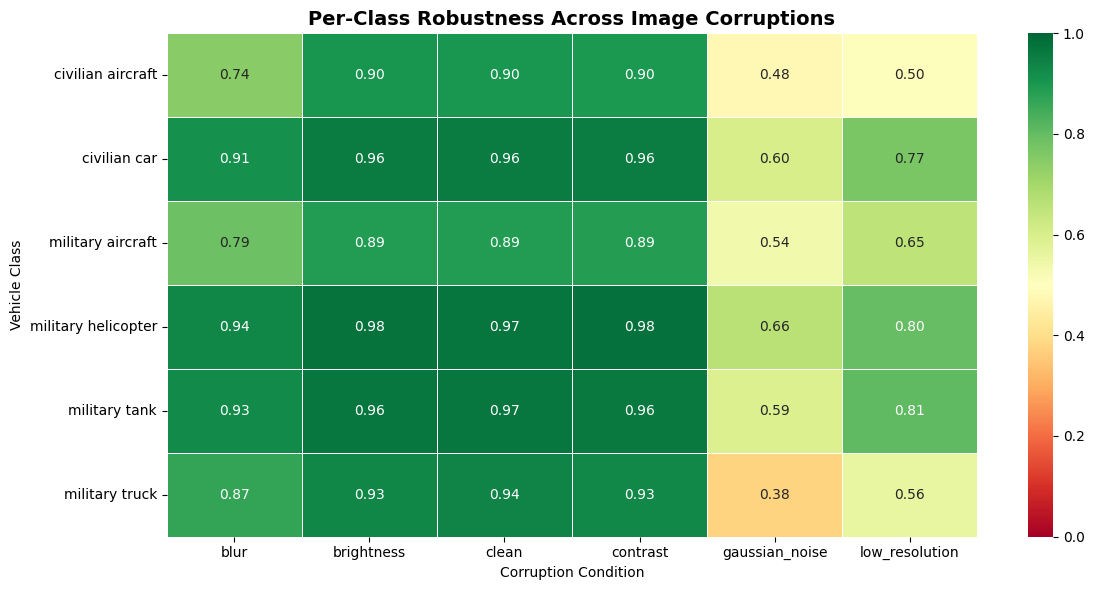

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.heatmap(
    robustness_pivot,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Per-Class Robustness Across Image Corruptions",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Corruption Condition")
plt.ylabel("Vehicle Class")

plt.tight_layout()
plt.show()

In [30]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [31]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Make sure we're using the champion model
model_tl.eval()

# Inspect the final feature block
print(model_tl.features[-1])

Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


In [32]:
target_layer = model_tl.features[-1]

cam = GradCAM(
    model=model_tl,
    target_layers=[target_layer]
)

print("Grad-CAM initialized successfully.")
print("Target layer:", target_layer)

Grad-CAM initialized successfully.
Target layer: Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


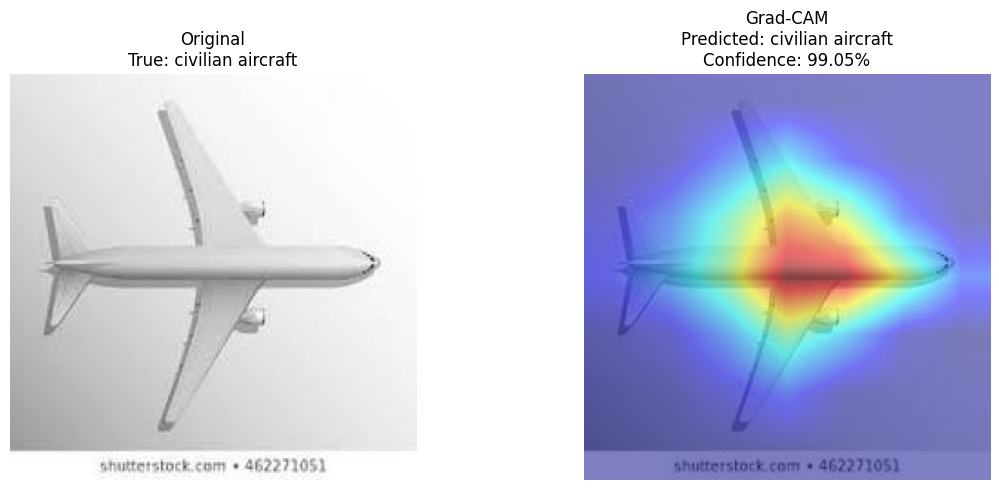

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Choose a test image
sample_idx = 100

image_path, true_label = test_dataset.samples[sample_idx]

# Load original image
original_image = Image.open(image_path).convert("RGB")

# Prepare model input
input_tensor = eval_transform(original_image).unsqueeze(0).to(device)

# Model prediction
with torch.no_grad():
    output = model_tl(input_tensor)
    probabilities = torch.softmax(output, dim=1)

predicted_label = output.argmax(dim=1).item()
confidence = probabilities[0, predicted_label].item()

# Generate Grad-CAM for predicted class
targets = [
    ClassifierOutputTarget(predicted_label)
]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

# Resize/normalize original image for overlay
rgb_image = np.array(
    original_image.resize((IMG_SIZE, IMG_SIZE))
).astype(np.float32) / 255.0

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title(
    f"Original\nTrue: {test_dataset.classes[true_label]}"
)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title(
    f"Grad-CAM\nPredicted: {test_dataset.classes[predicted_label]}\n"
    f"Confidence: {confidence:.2%}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

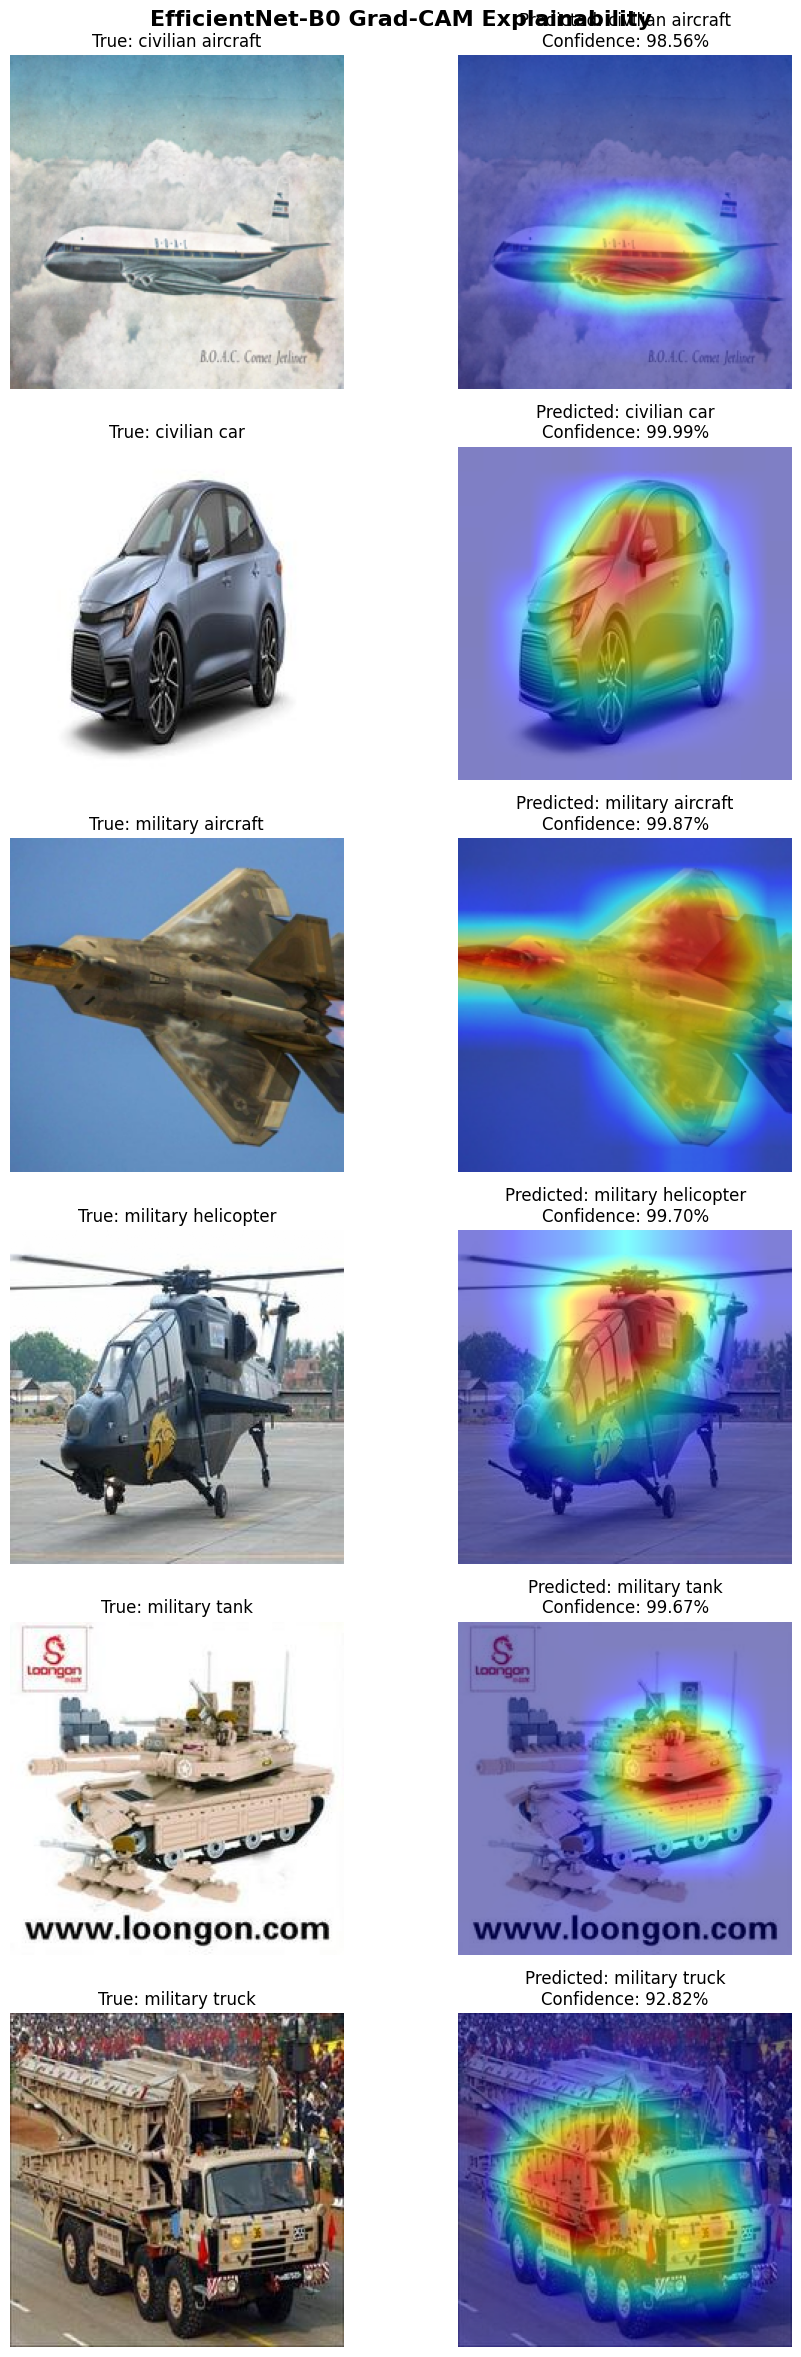

In [34]:
import random
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Find one test image from each class
class_samples = {}

for idx, (image_path, label) in enumerate(test_dataset.samples):
    if label not in class_samples:
        class_samples[label] = idx

# Create figure
fig, axes = plt.subplots(
    len(class_samples),
    2,
    figsize=(10, 4 * len(class_samples))
)

for row, (label, sample_idx) in enumerate(
    sorted(class_samples.items())
):

    image_path, true_label = test_dataset.samples[sample_idx]

    original_image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = eval_transform(
        original_image
    ).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        output = model_tl(input_tensor)
        probabilities = torch.softmax(
            output,
            dim=1
        )

    predicted_label = output.argmax(
        dim=1
    ).item()

    confidence = probabilities[
        0,
        predicted_label
    ].item()

    # Grad-CAM
    targets = [
        ClassifierOutputTarget(
            predicted_label
        )
    ]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    rgb_image = np.array(
        original_image.resize(
            (IMG_SIZE, IMG_SIZE)
        )
    ).astype(np.float32) / 255.0

    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    # Original
    axes[row, 0].imshow(rgb_image)
    axes[row, 0].set_title(
        f"True: {test_dataset.classes[true_label]}"
    )
    axes[row, 0].axis("off")

    # Grad-CAM
    axes[row, 1].imshow(visualization)
    axes[row, 1].set_title(
        f"Predicted: {test_dataset.classes[predicted_label]}\n"
        f"Confidence: {confidence:.2%}"
    )
    axes[row, 1].axis("off")

plt.suptitle(
    "EfficientNet-B0 Grad-CAM Explainability",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [35]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def predict_top_k(
    model,
    image,
    transform,
    class_names,
    k=5
):
    model.eval()

    input_tensor = transform(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.softmax(
            logits,
            dim=1
        )

    top_probs, top_indices = torch.topk(
        probabilities,
        k=min(k, len(class_names)),
        dim=1
    )

    top_probs = top_probs[0].cpu().numpy()
    top_indices = top_indices[0].cpu().numpy()

    results = []

    for probability, index in zip(
        top_probs,
        top_indices
    ):
        results.append({
            "class": class_names[index],
            "probability": float(probability)
        })

    # Entropy-based uncertainty
    probs = probabilities[0]
    entropy = -torch.sum(
        probs * torch.log(
            probs + 1e-12
        )
    )

    max_entropy = np.log(
        len(class_names)
    )

    normalized_uncertainty = (
        entropy.item() / max_entropy
    )

    return results, normalized_uncertainty


# Test on the same sample
sample_idx = 100

image_path, true_label = test_dataset.samples[
    sample_idx
]

image = Image.open(
    image_path
).convert("RGB")

results, uncertainty = predict_top_k(
    model_tl,
    image,
    eval_transform,
    test_dataset.classes,
    k=5
)

print(
    "True class:",
    test_dataset.classes[true_label]
)

print("\nTop-K Predictions:")

for rank, result in enumerate(
    results,
    start=1
):
    print(
        f"{rank}. "
        f"{result['class']:<22} "
        f"{result['probability']:.2%}"
    )

print(
    f"\nNormalized uncertainty: "
    f"{uncertainty:.4f}"
)

True class: civilian aircraft

Top-K Predictions:
1. civilian aircraft      99.05%
2. military aircraft      0.93%
3. military tank          0.02%
4. military helicopter    0.00%
5. civilian car           0.00%

Normalized uncertainty: 0.0306


In [36]:
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
import torch

confidence_records = []

model_tl.eval()

for idx in range(len(test_dataset)):

    image_path, true_label = test_dataset.samples[idx]

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = eval_transform(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model_tl(input_tensor)

        probabilities = torch.softmax(
            logits,
            dim=1
        )

    predicted_label = probabilities.argmax(
        dim=1
    ).item()

    confidence = probabilities[
        0,
        predicted_label
    ].item()

    entropy = -torch.sum(
        probabilities[0] *
        torch.log(
            probabilities[0] + 1e-12
        )
    ).item()

    normalized_uncertainty = (
        entropy / np.log(len(test_dataset.classes))
    )

    confidence_records.append({
        "True Class": test_dataset.classes[true_label],
        "Predicted Class": test_dataset.classes[predicted_label],
        "Confidence": confidence,
        "Uncertainty": normalized_uncertainty,
        "Correct": predicted_label == true_label
    })

confidence_df = pd.DataFrame(
    confidence_records
)

print("Confidence analysis complete.")
print(
    f"Test samples analyzed: "
    f"{len(confidence_df)}"
)

print(
    f"Mean confidence: "
    f"{confidence_df['Confidence'].mean():.4f}"
)

print(
    f"Median confidence: "
    f"{confidence_df['Confidence'].median():.4f}"
)

print(
    f"Mean uncertainty: "
    f"{confidence_df['Uncertainty'].mean():.4f}"
)

Confidence analysis complete.
Test samples analyzed: 1512
Mean confidence: 0.9638
Median confidence: 0.9985
Mean uncertainty: 0.0632


In [37]:
high_conf_wrong = confidence_df[
    (confidence_df["Correct"] == False) &
    (confidence_df["Confidence"] >= 0.90)
].copy()

high_conf_wrong = high_conf_wrong.sort_values(
    "Confidence",
    ascending=False
)

print(
    f"High-confidence wrong predictions: "
    f"{len(high_conf_wrong)}"
)

print(
    f"Percentage of test set: "
    f"{len(high_conf_wrong) / len(confidence_df):.2%}"
)

print("\nTop 20 highest-confidence mistakes:")

display(
    high_conf_wrong.head(20)
)

High-confidence wrong predictions: 43
Percentage of test set: 2.84%

Top 20 highest-confidence mistakes:


,True Class,Predicted Class,Confidence,Uncertainty,Correct
1355,military truck,civilian car,0.999999,0.000009,False
647,military aircraft,civilian aircraft,0.999990,0.000074,False
821,military helicopter,civilian car,0.999965,0.000249,False
1297,military tank,civilian car,0.999954,0.000310,False
1330,military truck,military tank,0.999948,0.000348,False
31,civilian aircraft,military aircraft,0.999855,0.000896,False
62,civilian aircraft,military aircraft,0.999795,0.001147,False
185,civilian aircraft,military aircraft,0.999759,0.001350,False
193,civilian aircraft,military aircraft,0.999750,0.001396,False
204,civilian aircraft,military aircraft,0.999732,0.001469,False


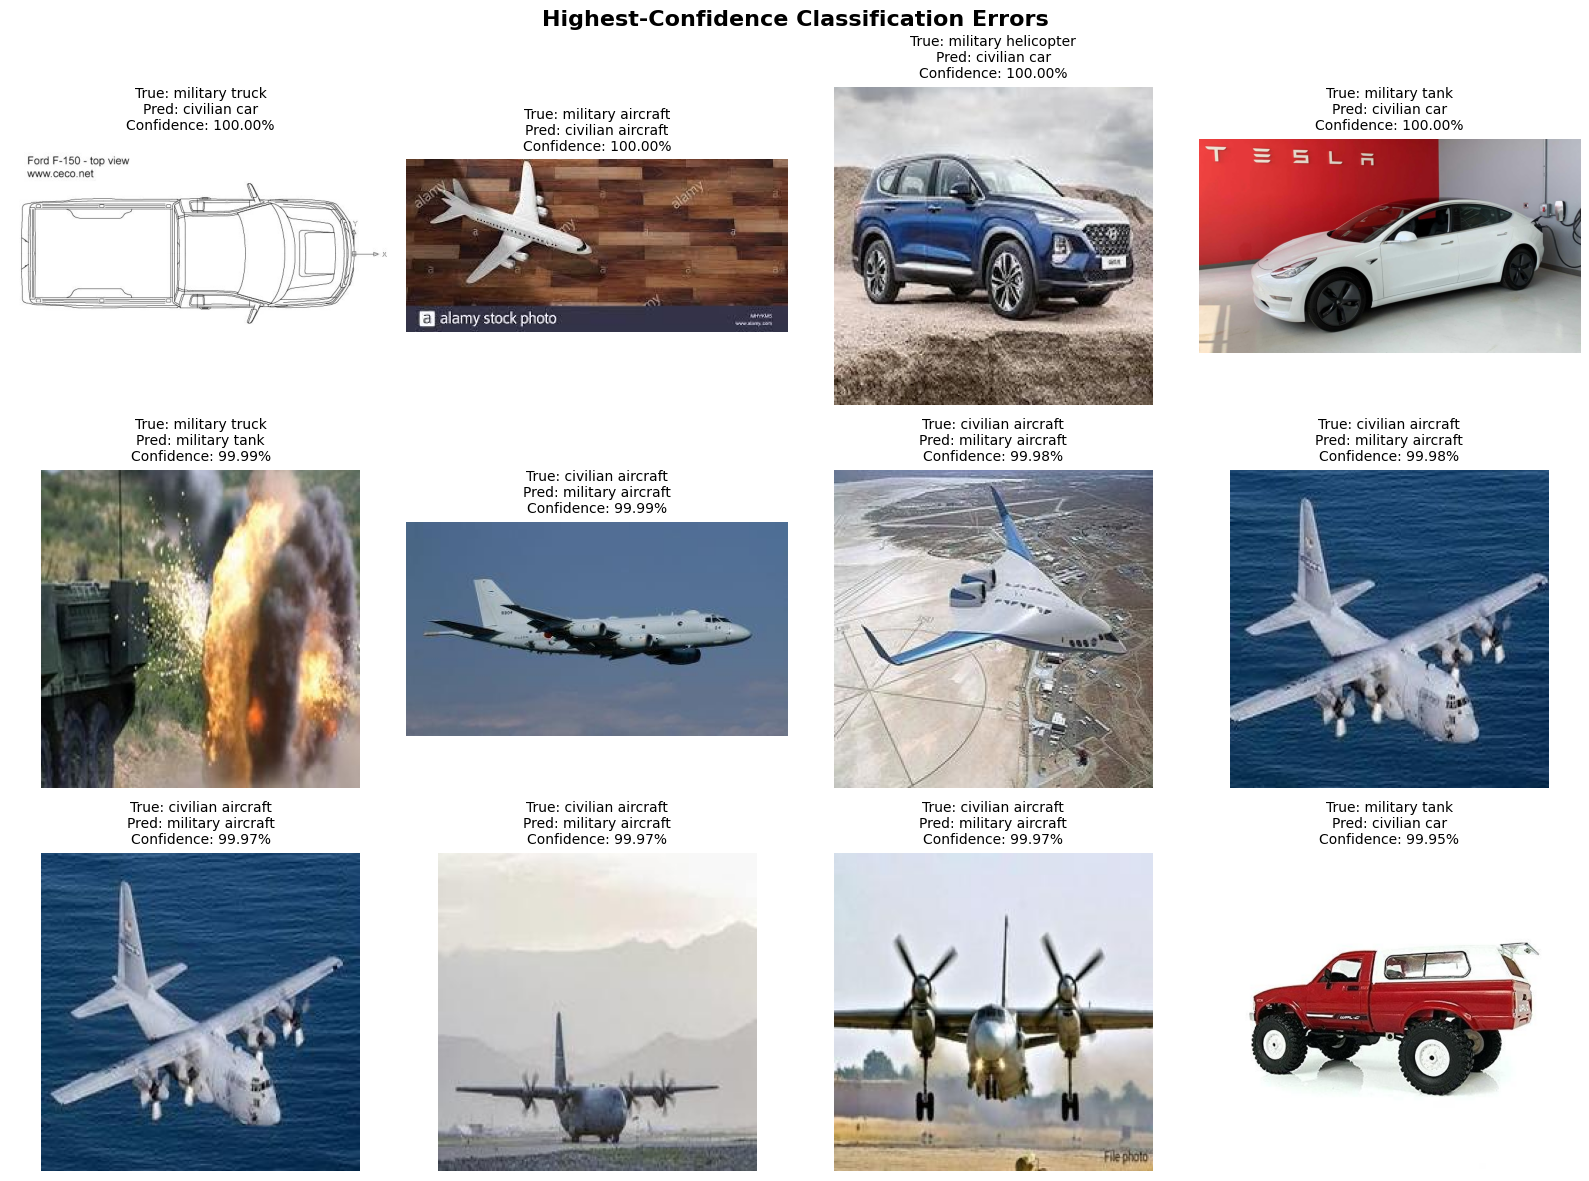

In [38]:
import matplotlib.pyplot as plt
from PIL import Image

# Select the 12 most confident mistakes
top_errors = high_conf_wrong.head(12)

fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12)
)

for ax, (sample_idx, row) in zip(
    axes.flat,
    top_errors.iterrows()
):

    image_path, true_label = test_dataset.samples[
        sample_idx
    ]

    image = Image.open(
        image_path
    ).convert("RGB")

    ax.imshow(image)

    ax.set_title(
        f"True: {row['True Class']}\n"
        f"Pred: {row['Predicted Class']}\n"
        f"Confidence: {row['Confidence']:.2%}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "Highest-Confidence Classification Errors",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

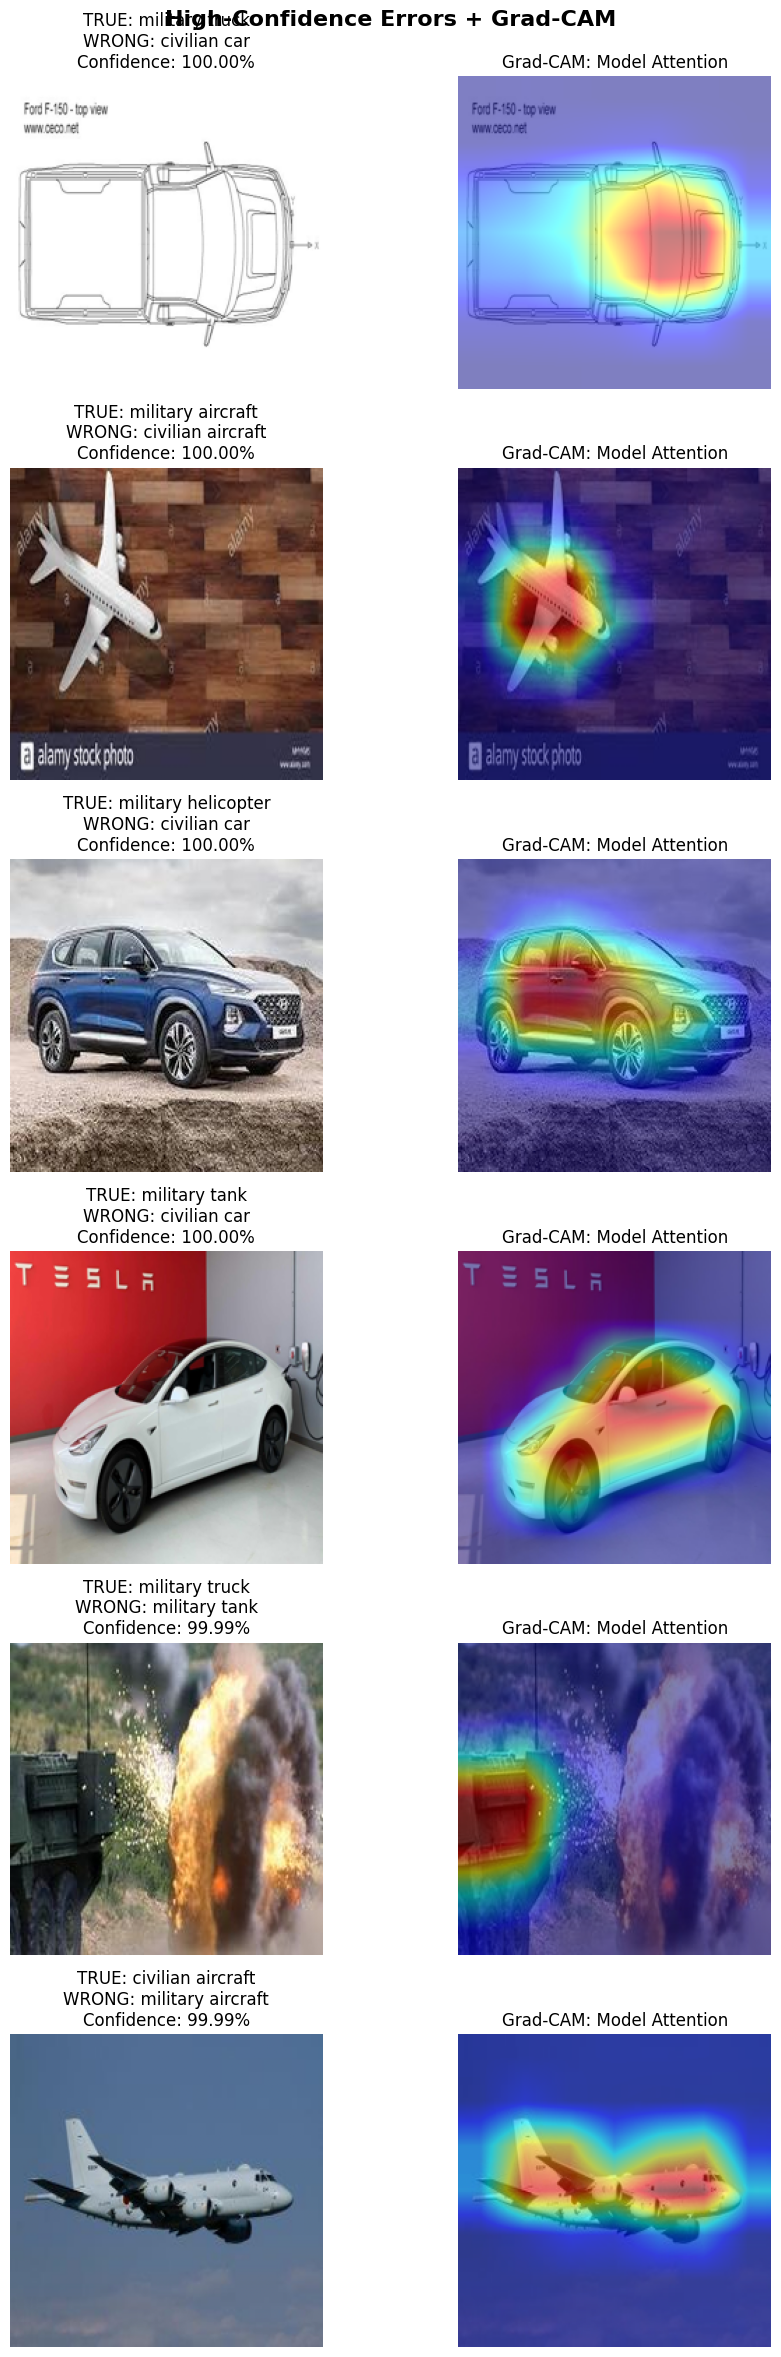

In [39]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

top_errors = high_conf_wrong.head(6)

fig, axes = plt.subplots(
    6,
    2,
    figsize=(10, 24)
)

for row_idx, (sample_idx, row) in enumerate(
    top_errors.iterrows()
):

    image_path, true_label = test_dataset.samples[
        sample_idx
    ]

    original_image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = eval_transform(
        original_image
    ).unsqueeze(0).to(device)

    predicted_label = test_dataset.classes.index(
        row["Predicted Class"]
    )

    targets = [
        ClassifierOutputTarget(
            predicted_label
        )
    ]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    rgb_image = np.array(
        original_image.resize(
            (IMG_SIZE, IMG_SIZE)
        )
    ).astype(np.float32) / 255.0

    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    # Original
    axes[row_idx, 0].imshow(rgb_image)

    axes[row_idx, 0].set_title(
        f"TRUE: {row['True Class']}\n"
        f"WRONG: {row['Predicted Class']}\n"
        f"Confidence: {row['Confidence']:.2%}"
    )

    axes[row_idx, 0].axis("off")

    # Grad-CAM
    axes[row_idx, 1].imshow(
        visualization
    )

    axes[row_idx, 1].set_title(
        "Grad-CAM: Model Attention"
    )

    axes[row_idx, 1].axis("off")

plt.suptitle(
    "High-Confidence Errors + Grad-CAM",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

military_classes = {
    "military aircraft",
    "military helicopter",
    "military tank",
    "military truck"
}

binary_records = []

model_tl.eval()

for idx in range(len(test_dataset)):

    image_path, true_label = test_dataset.samples[idx]

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = eval_transform(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model_tl(input_tensor)

        probabilities = torch.softmax(
            logits,
            dim=1
        )[0]

    # Aggregate six-class probabilities
    military_probability = sum(
        probabilities[class_idx].item()
        for class_idx, class_name
        in enumerate(test_dataset.classes)
        if class_name in military_classes
    )

    civilian_probability = 1.0 - military_probability

    true_class = test_dataset.classes[
        true_label
    ]

    true_binary = (
        1
        if true_class in military_classes
        else 0
    )

    predicted_binary = (
        1
        if military_probability >= 0.5
        else 0
    )

    binary_records.append({
        "True Class": true_class,
        "True Binary": true_binary,
        "Military Probability": military_probability,
        "Civilian Probability": civilian_probability,
        "Predicted Binary": predicted_binary,
        "Correct": true_binary == predicted_binary
    })

binary_df = pd.DataFrame(
    binary_records
)

y_true = binary_df["True Binary"]
y_pred = binary_df["Predicted Binary"]

print("=== Military vs Civilian Classification ===")

print(
    f"Accuracy:  "
    f"{accuracy_score(y_true, y_pred):.4f}"
)

print(
    f"Precision: "
    f"{precision_score(y_true, y_pred):.4f}"
)

print(
    f"Recall:    "
    f"{recall_score(y_true, y_pred):.4f}"
)

print(
    f"Macro-F1:  "
    f"{f1_score(y_true, y_pred, average='macro'):.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Civilian",
            "Military"
        ]
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_true,
        y_pred
    )
)

=== Military vs Civilian Classification ===
Accuracy:  0.9603
Precision: 0.9700
Recall:    0.9737
Macro-F1:  0.9524

Classification Report:
              precision    recall  f1-score   support

    Civilian       0.94      0.93      0.93       449
    Military       0.97      0.97      0.97      1063

    accuracy                           0.96      1512
   macro avg       0.95      0.95      0.95      1512
weighted avg       0.96      0.96      0.96      1512

Confusion Matrix:
[[ 417   32]
 [  28 1035]]


In [42]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
    )

def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

baseline_params = count_parameters(
    baseline_model
)

baseline_trainable = count_trainable_parameters(
    baseline_model
)

efficientnet_params = count_parameters(
    model_tl
)

efficientnet_trainable = count_trainable_parameters(
    model_tl
)

print("=== MODEL BATTLE ARENA ===")

print("\nBaseline CNN")
print(
    f"Total parameters: "
    f"{baseline_params:,}"
)
print(
    f"Trainable parameters: "
    f"{baseline_trainable:,}"
)

print("\nEfficientNet-B0")
print(
    f"Total parameters: "
    f"{efficientnet_params:,}"
)
print(
    f"Trainable parameters: "
    f"{efficientnet_trainable:,}"
)

NameError: name 'baseline_model' is not defined

In [46]:
print("Current model variables:")

for name, value in globals().items():
    if isinstance(value, torch.nn.Module):
        print(
            f"{name}: "
            f"{value.__class__.__name__}"
        )

Current model variables:
model: BaselineCNN
criterion: CrossEntropyLoss
model_tl: EfficientNet
criterion_tl: CrossEntropyLoss
model_ft: EfficientNet
criterion_ft: CrossEntropyLoss
model_robust: EfficientNet
target_layer: Conv2dNormActivation


In [47]:
print("Current model variables:")

for name, value in list(globals().items()):
    if isinstance(value, torch.nn.Module):
        print(
            f"{name}: "
            f"{value.__class__.__name__}"
        )

Current model variables:
model: BaselineCNN
criterion: CrossEntropyLoss
model_tl: EfficientNet
criterion_tl: CrossEntropyLoss
model_ft: EfficientNet
criterion_ft: CrossEntropyLoss
model_robust: EfficientNet
target_layer: Conv2dNormActivation


In [48]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
    )

def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

baseline_params = count_parameters(model)
baseline_trainable = count_trainable_parameters(model)

efficientnet_params = count_parameters(model_tl)
efficientnet_trainable = count_trainable_parameters(model_tl)

print("=== MODEL BATTLE ARENA ===")

print("\nBaseline CNN")
print(f"Total parameters: {baseline_params:,}")
print(f"Trainable parameters: {baseline_trainable:,}")

print("\nEfficientNet-B0")
print(f"Total parameters: {efficientnet_params:,}")
print(f"Trainable parameters: {efficientnet_trainable:,}")

=== MODEL BATTLE ARENA ===

Baseline CNN
Total parameters: 389,958
Trainable parameters: 389,958

EfficientNet-B0
Total parameters: 4,015,234
Trainable parameters: 4,015,234


In [49]:
import pandas as pd

baseline_accuracy = 0.6422
baseline_macro_f1 = 0.6343

efficientnet_accuracy = 0.9411
efficientnet_macro_f1 = 0.9376

battle_df = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Parameters": baseline_params,
        "Test Accuracy": baseline_accuracy,
        "Test Macro-F1": baseline_macro_f1,
        "Validation Macro-F1": 0.6434
    },
    {
        "Model": "EfficientNet-B0",
        "Parameters": efficientnet_params,
        "Test Accuracy": efficientnet_accuracy,
        "Test Macro-F1": efficientnet_macro_f1,
        "Validation Macro-F1": 0.9549
    }
])

battle_df["Accuracy (%)"] = (
    battle_df["Test Accuracy"] * 100
)

battle_df["Macro-F1 (%)"] = (
    battle_df["Test Macro-F1"] * 100
)

battle_df["Parameter Count (M)"] = (
    battle_df["Parameters"] / 1_000_000
)

display(
    battle_df[
        [
            "Model",
            "Parameter Count (M)",
            "Accuracy (%)",
            "Macro-F1 (%)",
            "Validation Macro-F1"
        ]
    ].round(2)
)

accuracy_gain = (
    efficientnet_accuracy -
    baseline_accuracy
) * 100

f1_gain = (
    efficientnet_macro_f1 -
    baseline_macro_f1
) * 100

parameter_multiplier = (
    efficientnet_params /
    baseline_params
)

print(
    f"\nAccuracy improvement: "
    f"+{accuracy_gain:.2f} percentage points"
)

print(
    f"Macro-F1 improvement: "
    f"+{f1_gain:.2f} percentage points"
)

print(
    f"Parameter increase: "
    f"{parameter_multiplier:.2f}×"
)

,Model,Parameter Count (M),Accuracy (%),Macro-F1 (%),Validation Macro-F1
0,Baseline CNN,0.39,64.22,63.43,0.64
1,EfficientNet-B0,4.02,94.11,93.76,0.95



Accuracy improvement: +29.89 percentage points
Macro-F1 improvement: +30.33 percentage points
Parameter increase: 10.30×


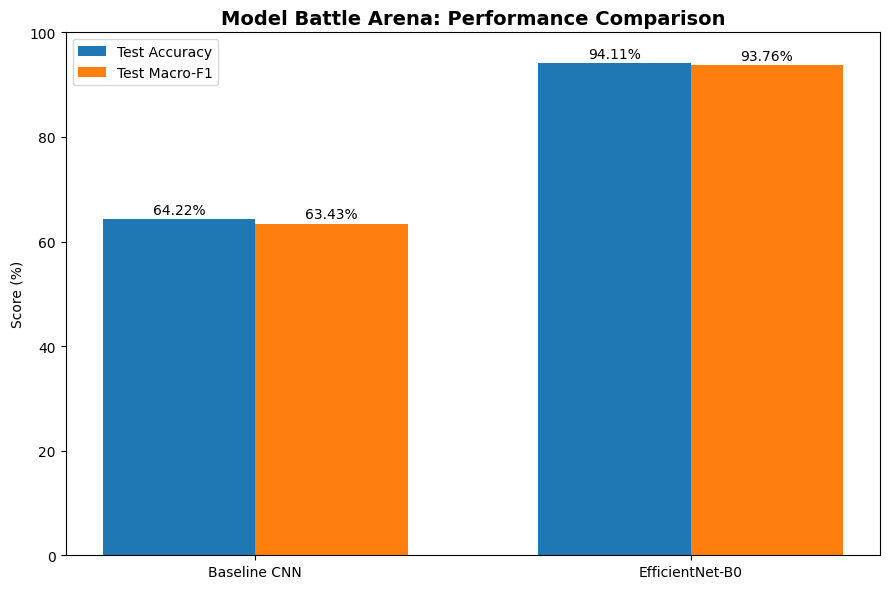

In [50]:
import matplotlib.pyplot as plt
import numpy as np

models = battle_df["Model"].tolist()
accuracy = battle_df["Accuracy (%)"].tolist()
macro_f1 = battle_df["Macro-F1 (%)"].tolist()

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    accuracy,
    width,
    label="Test Accuracy"
)

plt.bar(
    x + width / 2,
    macro_f1,
    width,
    label="Test Macro-F1"
)

plt.xticks(
    x,
    models
)

plt.ylabel("Score (%)")
plt.ylim(0, 100)

plt.title(
    "Model Battle Arena: Performance Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.legend()

for i in range(len(models)):
    plt.text(
        i - width / 2,
        accuracy[i] + 1,
        f"{accuracy[i]:.2f}%",
        ha="center"
    )

    plt.text(
        i + width / 2,
        macro_f1[i] + 1,
        f"{macro_f1[i]:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [51]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Count samples in each split
split_counts = {}

for split_name, split_dataset in [
    ("Training", train_dataset),
    ("Validation", val_dataset),
    ("Testing", test_dataset)
]:

    counts = Counter(
        label
        for _, label in split_dataset.samples
    )

    split_counts[split_name] = [
        counts[i]
        for i in range(len(split_dataset.classes))
    ]

distribution_df = pd.DataFrame(
    split_counts,
    index=train_dataset.classes
)

print("=== DATASET CLASS DISTRIBUTION ===")
display(distribution_df)

print("\nTotal samples by split:")
print(distribution_df.sum())

print("\nClass totals:")
print(distribution_df.sum(axis=1))

=== DATASET CLASS DISTRIBUTION ===


,Training,Validation,Testing
civilian aircraft,812,143,220
civilian car,871,153,229
military aircraft,829,147,228
military helicopter,993,175,264
military tank,1373,242,358
military truck,818,145,213



Total samples by split:
Training      5696
Validation    1005
Testing       1512
dtype: int64

Class totals:
civilian aircraft      1175
civilian car           1253
military aircraft      1204
military helicopter    1432
military tank          1973
military truck         1176
dtype: int64


=== CLASS IMBALANCE ANALYSIS ===
Total images: 8,213
Largest class: military tank
Smallest class: civilian aircraft
Imbalance ratio: 1.68x

=== CLASS SHARE ===
military tank         : 24.02%
military helicopter   : 17.44%
civilian car          : 15.26%
military aircraft     : 14.66%
military truck        : 14.32%
civilian aircraft     : 14.31%


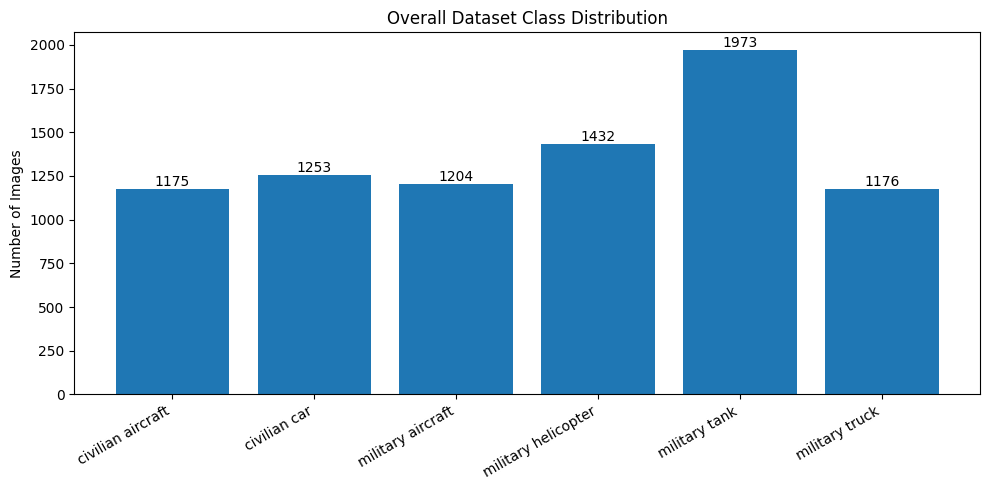

In [52]:
# Dataset Forensics — imbalance analysis

import numpy as np
import matplotlib.pyplot as plt

# Total samples across all splits
class_totals = distribution_df.sum(axis=1)

# Imbalance ratio
imbalance_ratio = class_totals.max() / class_totals.min()

# Percentage share of each class
class_share = (class_totals / class_totals.sum() * 100).sort_values(ascending=False)

print("=== CLASS IMBALANCE ANALYSIS ===")
print(f"Total images: {class_totals.sum():,}")
print(f"Largest class: {class_totals.idxmax()}")
print(f"Smallest class: {class_totals.idxmin()}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}x")

print("\n=== CLASS SHARE ===")
for cls, pct in class_share.items():
    print(f"{cls:22s}: {pct:.2f}%")

# Visualize overall class distribution
plt.figure(figsize=(10, 5))

bars = plt.bar(
    class_totals.index,
    class_totals.values
)

plt.title("Overall Dataset Class Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=30, ha="right")

for bar, value in zip(bars, class_totals.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

=== CLASS DISTRIBUTION BY SPLIT (%) ===


,Training,Validation,Testing
civilian aircraft,14.26,14.23,14.55
civilian car,15.29,15.22,15.15
military aircraft,14.55,14.63,15.08
military helicopter,17.43,17.41,17.46
military tank,24.10,24.08,23.68
military truck,14.36,14.43,14.09


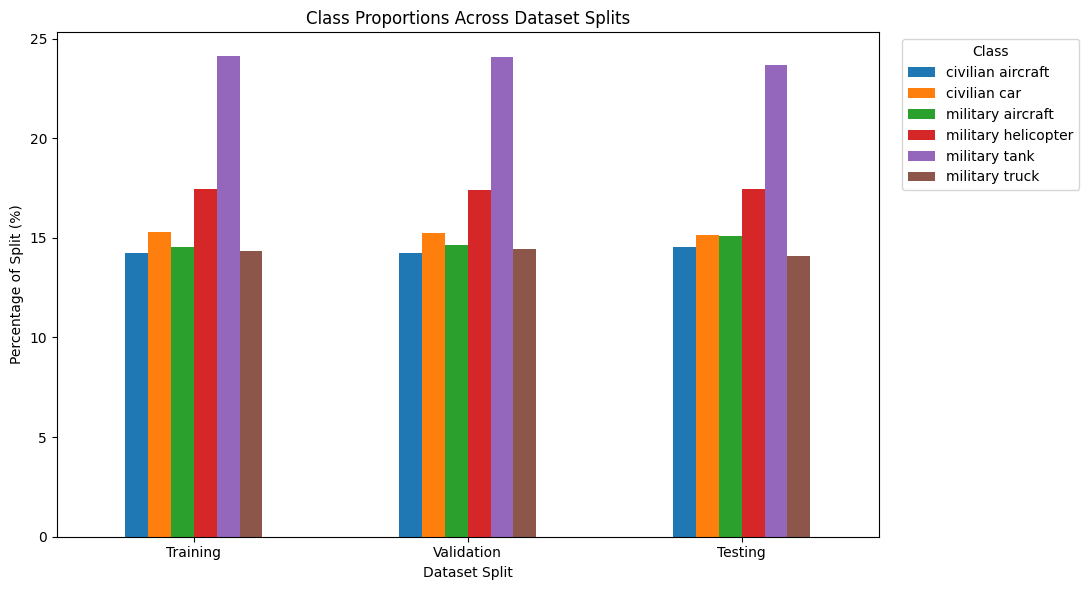

In [53]:
# Dataset Forensics — split consistency

split_percentages = distribution_df.div(
    distribution_df.sum(axis=0),
    axis=1
) * 100

print("=== CLASS DISTRIBUTION BY SPLIT (%) ===")
display(split_percentages.round(2))

# Plot split proportions
ax = split_percentages.T.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("Class Proportions Across Dataset Splits")
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Percentage of Split (%)")
ax.legend(
    title="Class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [54]:
# ============================================================
# EMBEDDING EXPLORER — STEP 1
# Extract validation-set feature embeddings
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F

model_tl.eval()

embedding_features = []
embedding_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        # EfficientNet feature extractor
        features = model_tl.features(images)

        # Global average pooling
        features = F.adaptive_avg_pool2d(
            features,
            (1, 1)
        )

        # Flatten: [batch, 1280]
        features = torch.flatten(
            features,
            start_dim=1
        )

        # L2 normalization
        features = F.normalize(
            features,
            p=2,
            dim=1
        )

        embedding_features.append(
            features.cpu().numpy()
        )

        embedding_labels.append(
            labels.numpy()
        )

# Combine all batches
embedding_features = np.concatenate(
    embedding_features,
    axis=0
)

embedding_labels = np.concatenate(
    embedding_labels,
    axis=0
)

print("=== EMBEDDING EXTRACTION COMPLETE ===")
print(f"Samples: {embedding_features.shape[0]}")
print(f"Embedding dimensions: {embedding_features.shape[1]}")
print(f"Feature matrix shape: {embedding_features.shape}")

=== EMBEDDING EXTRACTION COMPLETE ===
Samples: 1005
Embedding dimensions: 1280
Feature matrix shape: (1005, 1280)


In [55]:
# ============================================================
# EMBEDDING EXPLORER — STEP 2
# UMAP projection: 1280D → 2D
# ============================================================

!pip install -q umap-learn

import umap
import matplotlib.pyplot as plt

print("Running UMAP projection...")

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)

embedding_2d = reducer.fit_transform(
    embedding_features
)

print("=== UMAP COMPLETE ===")
print(f"Original dimensions: {embedding_features.shape[1]}")
print(f"Projected dimensions: {embedding_2d.shape[1]}")
print(f"Projected shape: {embedding_2d.shape}")

Running UMAP projection...


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


=== UMAP COMPLETE ===
Original dimensions: 1280
Projected dimensions: 2
Projected shape: (1005, 2)


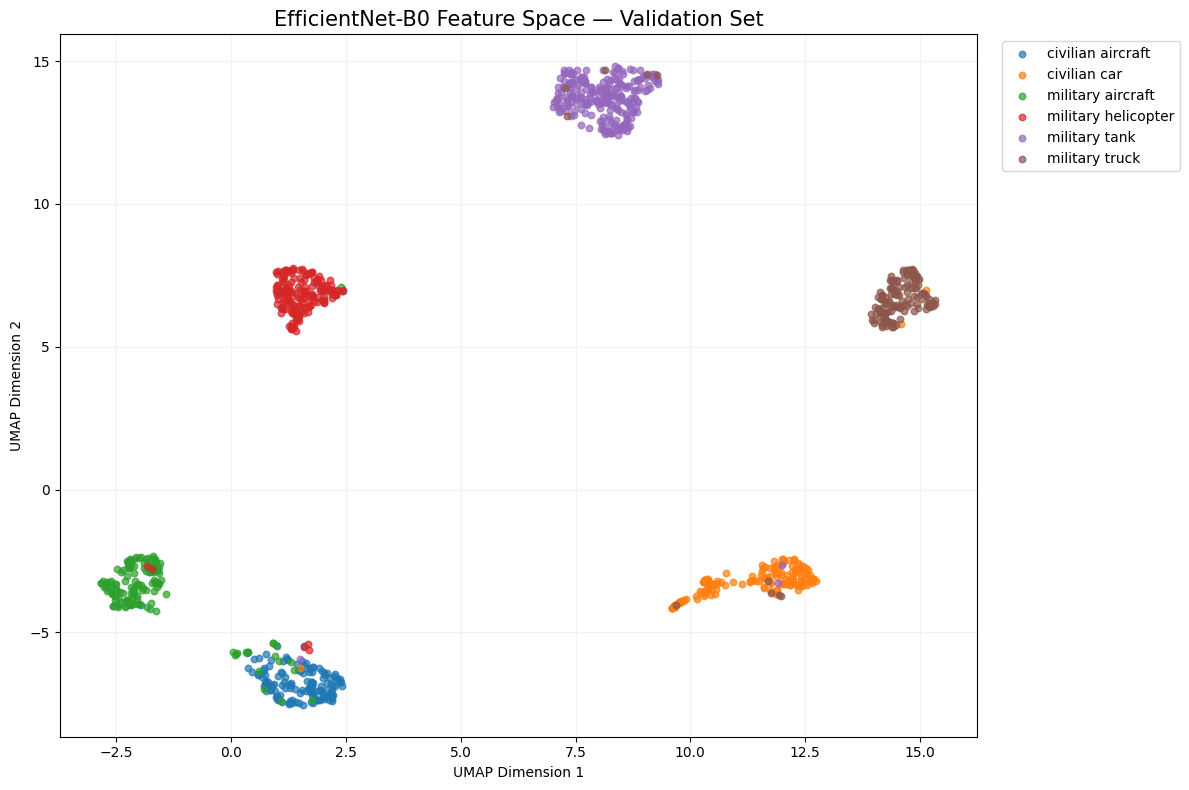

In [56]:
# ============================================================
# EMBEDDING EXPLORER — STEP 3
# Six-class UMAP visualization
# ============================================================

plt.figure(figsize=(12, 8))

classes = val_dataset.classes

for class_idx, class_name in enumerate(classes):

    mask = embedding_labels == class_idx

    plt.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        s=22,
        alpha=0.70,
        label=class_name
    )

plt.title(
    "EfficientNet-B0 Feature Space — Validation Set",
    fontsize=15
)

plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

In [57]:
# ============================================================
# INFERENCE BENCHMARK — STEP 1
# Compare CNN vs EfficientNet-B0 inference speed
# ============================================================

import time
import torch

def benchmark_model(model, loader, warmup_batches=5, benchmark_batches=30):

    model.eval()

    # Warm-up
    with torch.no_grad():
        for i, (images, _) in enumerate(loader):
            images = images.to(device)

            if device.type == "cuda":
                torch.cuda.synchronize()

            _ = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            if i + 1 >= warmup_batches:
                break

    total_images = 0
    total_time = 0.0

    with torch.no_grad():

        for i, (images, _) in enumerate(loader):

            images = images.to(device)

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            _ = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            end = time.perf_counter()

            total_time += end - start
            total_images += images.size(0)

            if i + 1 >= benchmark_batches:
                break

    latency_ms = (total_time / total_images) * 1000
    throughput = total_images / total_time

    return latency_ms, throughput


print("=== INFERENCE BENCHMARK ===")
print(f"Device: {device}")

cnn_latency, cnn_throughput = benchmark_model(
    model,
    val_loader
)

eff_latency, eff_throughput = benchmark_model(
    model_tl,
    val_loader
)

print("\nBaseline CNN")
print(f"Latency:    {cnn_latency:.3f} ms/image")
print(f"Throughput: {cnn_throughput:.2f} images/sec")

print("\nEfficientNet-B0")
print(f"Latency:    {eff_latency:.3f} ms/image")
print(f"Throughput: {eff_throughput:.2f} images/sec")

=== INFERENCE BENCHMARK ===
Device: cuda

Baseline CNN
Latency:    0.770 ms/image
Throughput: 1298.69 images/sec

EfficientNet-B0
Latency:    1.421 ms/image
Throughput: 703.70 images/sec


In [58]:
# ============================================================
# INFERENCE BENCHMARK — STEP 2
# Model size and efficiency analysis
# ============================================================

def get_model_stats(model):
    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    # FP32 parameter memory
    parameter_memory_mb = (
        total_params * 4
    ) / (1024 ** 2)

    return (
        total_params,
        trainable_params,
        parameter_memory_mb
    )


cnn_params, cnn_trainable, cnn_memory = get_model_stats(model)

eff_params, eff_trainable, eff_memory = get_model_stats(model_tl)

print("=== MODEL EFFICIENCY ANALYSIS ===")

print("\nBaseline CNN")
print(f"Parameters:        {cnn_params:,}")
print(f"Trainable:         {cnn_trainable:,}")
print(f"Parameter memory:  {cnn_memory:.2f} MB")

print("\nEfficientNet-B0")
print(f"Parameters:        {eff_params:,}")
print(f"Trainable:         {eff_trainable:,}")
print(f"Parameter memory:  {eff_memory:.2f} MB")

print("\n=== COMPARISON ===")

print(
    f"Parameter multiplier: "
    f"{eff_params / cnn_params:.2f}x"
)

print(
    f"Latency multiplier: "
    f"{eff_latency / cnn_latency:.2f}x"
)

print(
    f"Throughput ratio: "
    f"{eff_throughput / cnn_throughput:.2f}x"
)

print(
    f"Accuracy gain: "
    f"{94.11 - 64.22:.2f} percentage points"
)

print(
    f"Macro-F1 gain: "
    f"{93.76 - 63.43:.2f} percentage points"
)

=== MODEL EFFICIENCY ANALYSIS ===

Baseline CNN
Parameters:        389,958
Trainable:         389,958
Parameter memory:  1.49 MB

EfficientNet-B0
Parameters:        4,015,234
Trainable:         4,015,234
Parameter memory:  15.32 MB

=== COMPARISON ===
Parameter multiplier: 10.30x
Latency multiplier: 1.85x
Throughput ratio: 0.54x
Accuracy gain: 29.89 percentage points
Macro-F1 gain: 30.33 percentage points


In [59]:
import torch
import os

checkpoint_path = "/content/efficientnet_b0_vehicle_champion.pth"

torch.save({
    "model_state_dict": model_tl.state_dict(),
    "class_names": train_dataset.classes,
    "image_size": IMG_SIZE,
    "num_classes": 6,
    "architecture": "EfficientNet-B0",
    "test_accuracy": 94.11,
    "test_macro_f1": 93.76,
    "validation_macro_f1": 95.49,
    "seed": 42
}, checkpoint_path)

print("=== CHAMPION CHECKPOINT SAVED ===")
print(checkpoint_path)
print(f"Size: {os.path.getsize(checkpoint_path)/(1024**2):.2f} MB")

=== CHAMPION CHECKPOINT SAVED ===
/content/efficientnet_b0_vehicle_champion.pth
Size: 15.61 MB


In [60]:
from google.colab import drive
import shutil
import os

drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/Military_Vehicle_AI_Project"
os.makedirs(save_dir, exist_ok=True)

drive_checkpoint = os.path.join(
    save_dir,
    "efficientnet_b0_vehicle_champion.pth"
)

shutil.copy2(
    checkpoint_path,
    drive_checkpoint
)

print("=== CHECKPOINT BACKED UP ===")
print(drive_checkpoint)
print(f"Size: {os.path.getsize(drive_checkpoint)/(1024**2):.2f} MB")

Mounted at /content/drive
=== CHECKPOINT BACKED UP ===
/content/drive/MyDrive/Military_Vehicle_AI_Project/efficientnet_b0_vehicle_champion.pth
Size: 15.61 MB
